# Задание 1. Склейка панорамы

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

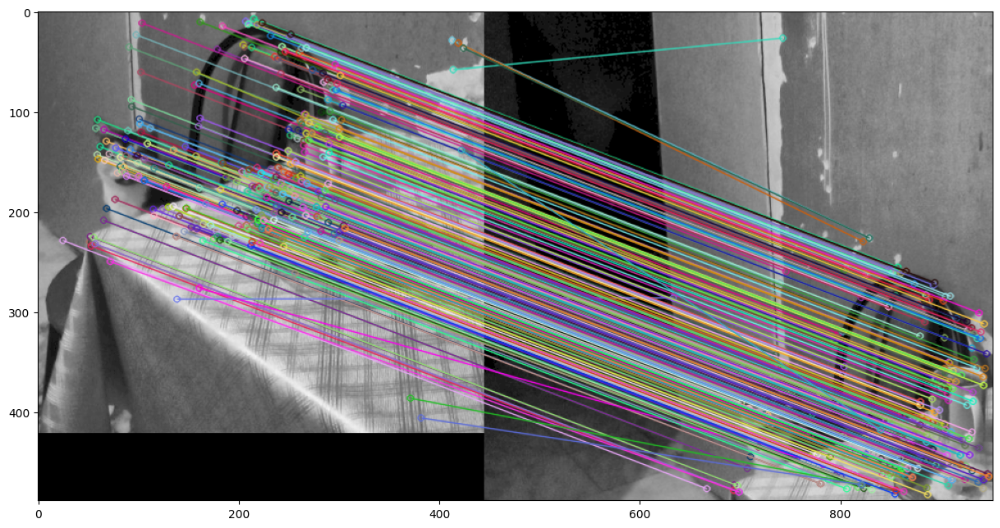

In [2]:
img1 = cv2.imread('../data/images/cat1.png', cv2.IMREAD_GRAYSCALE)       
img2 = cv2.imread('../data/images/cat2.png', cv2.IMREAD_GRAYSCALE)

sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)


good = []
for m, n in matches:
    if m.distance < 0.75*n.distance:
        good.append([m])

img3 = cv2.drawMatchesKnn(img1, kp1, img2, kp2, good, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(15, 10))
plt.imshow(img3)
plt.show()

In [3]:
def match_descriptors(img1, img2):
    sift = cv2.SIFT_create()

    kp1, des1 = sift.detectAndCompute(img1, None)
    kp2, des2 = sift.detectAndCompute(img2, None)
    
    bf = cv2.BFMatcher()
    matches = bf.knnMatch(des1, des2, k=2)
    
    
    good = []
    for m, n in matches:
        if m.distance < 0.75*n.distance:
            good.append(m)

    matched_points = []
    for match in good:
        idx1 = match.queryIdx
        idx2 = match.trainIdx

        point1 = kp1[idx1].pt
        point2 = kp2[idx2].pt
        matched_points.append([point1, point2])
        
    return np.array(matched_points)

In [4]:
points = match_descriptors(img1, img2)

In [5]:
points

array([[[ 24.55938911, 228.10548401],
        [221.55938721, 476.10546875]],

       [[ 51.35458374, 229.68080139],
        [248.35464478, 477.68096924]],

       [[ 51.80575562, 224.32649231],
        [248.80575562, 472.32647705]],

       ...,

       [[418.86053467,  31.03102493],
        [377.58456421, 229.30108643]],

       [[421.95611572, 137.90626526],
        [394.8828125 , 417.55731201]],

       [[423.93035889,  36.07726669],
        [383.64505005, 225.71569824]]], shape=(279, 2, 2))

In [6]:
M = cv2.findHomography(points[:, 0, :], points[:, 1, :], method=cv2.RANSAC)[0]

In [7]:
M

array([[1.00066214e+00, 1.20632345e-04, 1.96964885e+02],
       [5.64768406e-04, 1.00034865e+00, 2.47945368e+02],
       [1.10810229e-06, 3.88683365e-07, 1.00000000e+00]])

In [8]:
def stitch_images(img1, img2, M):
    h1, w1 = img1.shape
    h2, w2 = img2.shape

    canvas_h = max(h1, h2) * 3
    canvas_w = max(w1, w2) * 3

    center_y = canvas_h // 2
    center_x = canvas_w // 2

    canvas = np.zeros((canvas_h, canvas_w), dtype=np.uint8)

    offset_y = center_y - h2 // 2
    offset_x = center_x - w2 // 2

    canvas[offset_y:offset_y+h2, offset_x:offset_x+w2] = img2

    M_shifted = M.copy()

    M_shifted[0, 2] += offset_x
    M_shifted[1, 2] += offset_y

    warped_img1 = cv2.warpPerspective(img1, M_shifted, (canvas_w, canvas_h))
    combined = np.maximum(canvas, warped_img1)

    plt.figure(figsize=(10, 10))
    plt.imshow(combined, cmap='gray')
    plt.axis('off')
    plt.show()

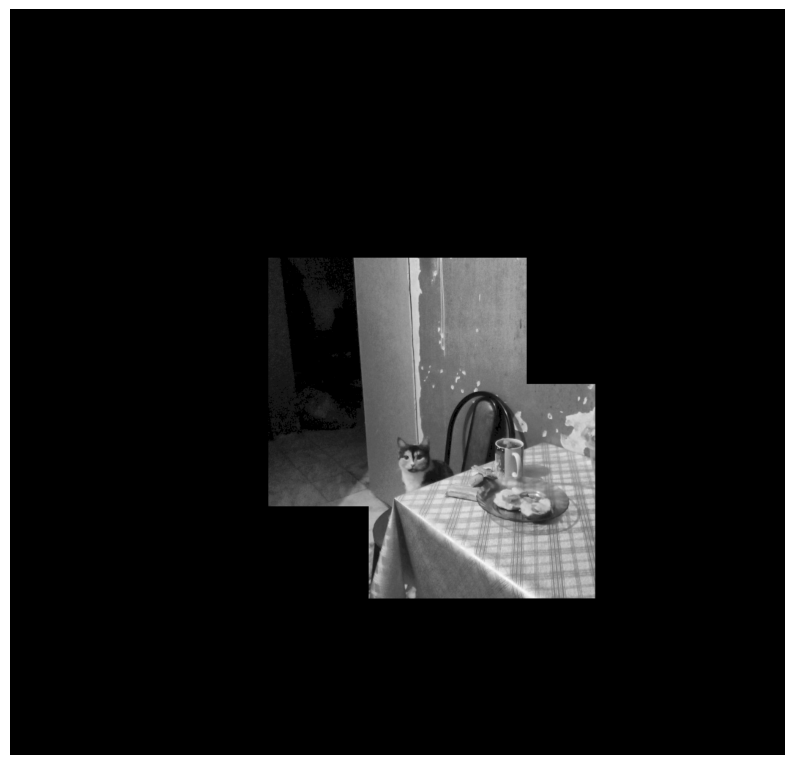

In [9]:
stitch_images(img1, img2, M)

# Задание 2. Оптический поток Лукаса-Канаде

In [10]:
import cv2
import os
from math import ceil
import numpy as np
import matplotlib.pyplot as plt

In [11]:
video_path = '../data/videos/test_video6.mp4'
output_folder = '../data/images/video_frames'

In [12]:
n_frames = 9

In [13]:
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Ошибка: Не удалось открыть видео.")
    exit()

count = 0
frame_count = 0
step = 3
start_frame = 225

while count < n_frames:
    ret, frame = cap.read()
    if not ret:
        break
    
    if frame_count % step == 0 and frame_count > start_frame:
        cv2.imwrite(f"{output_folder}/step_frame_{count}.png", frame)
        count += 1
    frame_count += 1

cap.release()

In [14]:
color_frames = [cv2.imread(f"{output_folder}/step_frame_{i}.png", cv2.IMREAD_COLOR_RGB) for i in range(n_frames)]
frames = [cv2.imread(f"{output_folder}/step_frame_{i}.png", cv2.IMREAD_GRAYSCALE) for i in range(n_frames)]

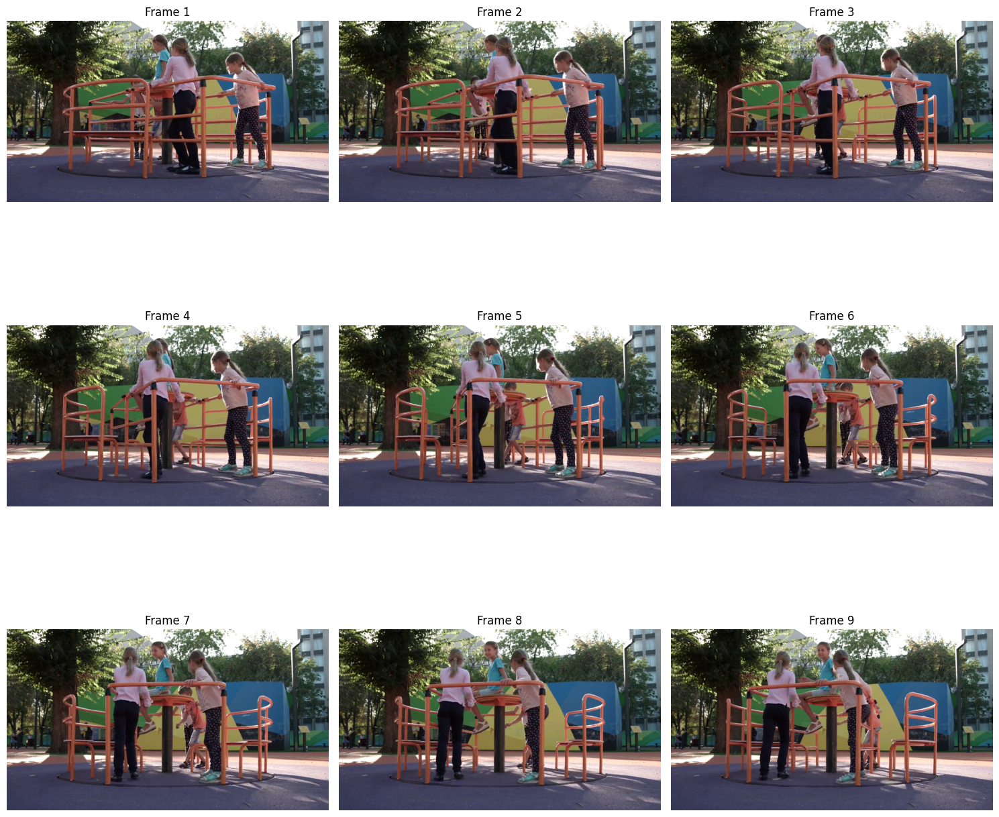

In [15]:
n_cols = 3
n_rows = ceil(n_frames / n_cols)

fig, axis = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axis = axis.flatten()

for i in range(len(color_frames)):
    ax = axis[i]
    ax.imshow(color_frames[i])
    ax.axis('off')
    ax.set_title(f'Frame {i+1}')

for j in range(i, len(axis)):
    axis[j].axis('off')


plt.tight_layout()

In [16]:
def lucas_kanade(img1, img2, window_size=3):
    pad = window_size // 2
    padded_img1 = np.pad(img1, ((pad, pad), (pad, pad)), mode='reflect').astype('float64')
    padded_img2 = np.pad(img2, ((pad, pad), (pad, pad)), mode='reflect').astype('float64')
    
    feature_params = dict(maxCorners=5000, qualityLevel=0.001, minDistance=5, blockSize=3)
    corners = cv2.goodFeaturesToTrack(img1, mask=None, **feature_params)

    grad_x = cv2.Sobel(padded_img1, cv2.CV_64F, 1, 0)
    grad_y = cv2.Sobel(padded_img1, cv2.CV_64F, 0, 1)
    optical_flow_vectors = []
    for point in corners:
        S = np.zeros((window_size ** 2, 2))
        T = np.zeros((window_size ** 2))
        
        point = point.flatten()
        k = 0
        for i in range(-pad, pad + 1):
            for j in range(-pad, pad + 1):
                x_cord = int(point[0] + i + pad)
                y_cord = int(point[1] + j + pad)
                
                S[k, 0] = grad_x[y_cord, x_cord]
                S[k, 1] = grad_y[y_cord, x_cord]

                T[k] = padded_img1[y_cord, x_cord] - padded_img2[y_cord, x_cord]
                k += 1
        sol = np.linalg.lstsq(S, T, rcond=None)[0]
        optical_flow_vectors.append(sol)
    return corners, np.array(optical_flow_vectors)

In [17]:
vectors = lucas_kanade(frames[1], frames[2])

In [18]:
def draw_optical_flow_vectors(img1, img2, color_img1, window_size, scale_factor_vectors):
    res = color_img1.copy()
    pad = window_size // 2

    padded_img1 = np.pad(img1, ((pad, pad), (pad, pad)), mode='reflect').astype('float64')
    padded_img2 = np.pad(img2, ((pad, pad), (pad, pad)), mode='reflect').astype('float64')
    points, vectors = lucas_kanade(img1, img2, window_size)

    lines = np.zeros_like(res)
    for p, v in zip(points, vectors):
        a, b = p.flatten().astype(int)
        c, d = (p.flatten() + scale_factor_vectors * v).astype(int)
        cv2.arrowedLine(lines, (a, b), (c, d), (0, 255, 0), 2)
        
    res = cv2.add(res, lines)
    return res

In [19]:
def draw_optical_flow_steps(frames, color_frames, window_size=21, scale_factor_vectors=1):
    n_frames = len(frames)
    n_cols = 1
    n_rows = ceil(n_frames / n_cols)
    
    fig, axis = plt.subplots(n_rows, n_cols, figsize=(15 * n_cols, 5 * n_rows))
    axis = axis.flatten()
    
    for i in range(len(color_frames) - 1):
        ax = axis[i]
        im = draw_optical_flow_vectors(frames[i], frames[i+1], color_frames[i], window_size, scale_factor_vectors)
        ax.imshow(im)
        ax.axis('off')
        ax.set_title(f'Frame {i+1}')
    
    for j in range(i, len(axis)):
        axis[j].axis('off')
    
    
    plt.tight_layout()
    plt.show()

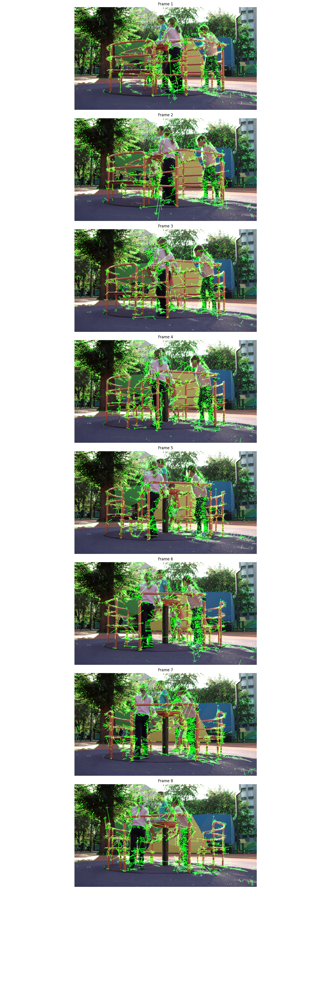

In [20]:
window = 21
scale = 120 
draw_optical_flow_steps(frames, color_frames, window, scale)